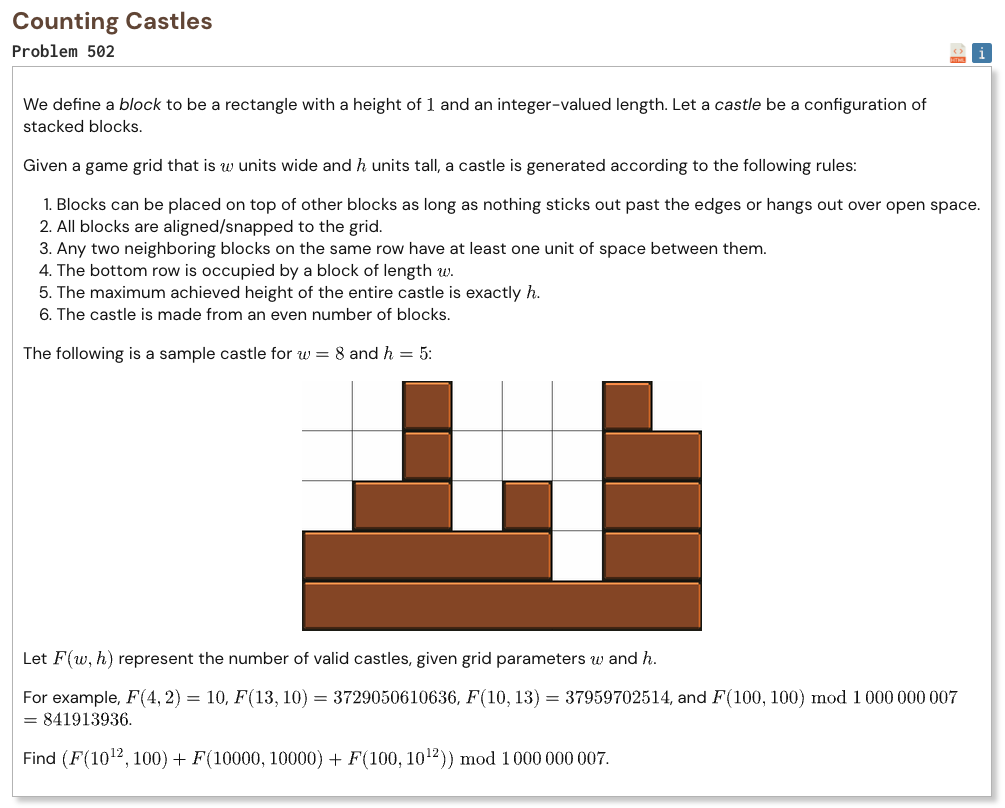

## Initial approach

- represent a castle by the height of each column
- track whether the current number of blocks is even or odd
- use dynamic programming with prefix and suffix sums to update all heights efficiently
- for huge width and small height, detect a linear recurrence and jump forward quickly
- for small width and huge height, the answer follows a polynomial pattern and can be interpolated
- use direct dynamic programming for the middle sized case
- use numpy to make the repeated array operations fast

In [1]:
%%time

import numpy as np

MOD = 1_000_000_007
INV2 = (MOD + 1) // 2

def step(dp0, dp1, alt):
    s0 = np.cumsum(dp0[::-1], dtype=np.int64)[::-1] % MOD
    s1 = np.cumsum(dp1[::-1], dtype=np.int64)[::-1] % MOD

    total = np.cumsum((dp0 + dp1) % MOD, dtype=np.int64) % MOD
    diff = (dp0 - dp1) % MOD
    alternating = np.cumsum((diff * alt) % MOD, dtype=np.int64) % MOD
    alternating = alternating * alt % MOD

    low0 = (total + alternating) * INV2 % MOD
    low1 = (total - alternating) * INV2 % MOD

    new0 = np.empty_like(dp0)
    new1 = np.empty_like(dp1)

    new0[:-1] = (s0[1:] + low0[:-1]) % MOD
    new1[:-1] = (s1[1:] + low1[:-1]) % MOD

    new0[-1] = low0[-1]
    new1[-1] = low1[-1]

    new0[0] = 0
    new1[0] = 0

    return new0, new1

def at_most(width, height):
    if height <= 0:
        return 0

    dp0 = np.zeros(height + 1, dtype=np.int64)
    dp1 = np.zeros(height + 1, dtype=np.int64)
    dp0[0] = 1

    alt = np.ones(height + 1, dtype=np.int64)
    alt[1::2] = MOD - 1

    for _ in range(width):
        dp0, dp1 = step(dp0, dp1, alt)

    return int(dp0[1:].sum() % MOD)

def direct_f(width, height):
    return (
        at_most(width, height)
        - at_most(width, height - 1)
    ) % MOD

def berlekamp_massey(sequence):
    C = [1]
    B = [1]

    L = 0
    m = 1
    b = 1

    for n in range(len(sequence)):
        d = sequence[n]

        for i in range(1, L + 1):
            d = (
                d
                + C[i] * sequence[n - i]
            ) % MOD

        if d == 0:
            m += 1
            continue

        factor = d * pow(b, MOD - 2, MOD) % MOD
        old = C[:]

        if len(C) < len(B) + m:
            C += [0] * (
                len(B) + m - len(C)
            )

        for i in range(len(B)):
            C[i + m] = (
                C[i + m]
                - factor * B[i]
            ) % MOD

        if 2 * L <= n:
            L = n + 1 - L
            B = old
            b = d
            m = 1
        else:
            m += 1

    return [
        (-C[i]) % MOD
        for i in range(1, L + 1)
    ]

def combine(a, b, recurrence):
    k = len(recurrence)
    temp = [0] * (2 * k)

    for i in range(k):
        for j in range(k):
            temp[i + j] = (
                temp[i + j]
                + a[i] * b[j]
            ) % MOD

    for i in range(2 * k - 2, k - 1, -1):
        for j in range(1, k + 1):
            temp[i - j] = (
                temp[i - j]
                + temp[i] * recurrence[j - 1]
            ) % MOD

    return temp[:k]

def nth_term(initial, recurrence, n):
    k = len(recurrence)

    if n < len(initial):
        return initial[n]

    result = [1] + [0] * (k - 1)
    base = [0] * k

    if k == 1:
        base[0] = recurrence[0]
    else:
        base[1] = 1

    while n:
        if n & 1:
            result = combine(
                result,
                base,
                recurrence
            )

        base = combine(
            base,
            base,
            recurrence
        )

        n //= 2

    return sum(
        result[i] * initial[i]
        for i in range(k)
    ) % MOD

def large_width(width, height):
    if height <= 0:
        return 0

    length = 8 * (height + 1) + 20

    dp0 = np.zeros(height + 1, dtype=np.int64)
    dp1 = np.zeros(height + 1, dtype=np.int64)
    dp0[0] = 1

    alt = np.ones(height + 1, dtype=np.int64)
    alt[1::2] = MOD - 1

    sequence = [0]

    for _ in range(1, length):
        dp0, dp1 = step(dp0, dp1, alt)
        sequence.append(
            int(dp0[1:].sum() % MOD)
        )

    recurrence = berlekamp_massey(sequence)
    initial = sequence[:len(recurrence)]

    return nth_term(
        initial,
        recurrence,
        width
    )

def interpolate(values, x):
    n = len(values) - 1

    factorial = [1] * (n + 1)

    for i in range(1, n + 1):
        factorial[i] = (
            factorial[i - 1] * i
        ) % MOD

    inverse_factorial = [1] * (n + 1)
    inverse_factorial[n] = pow(
        factorial[n],
        MOD - 2,
        MOD
    )

    for i in range(n, 0, -1):
        inverse_factorial[i - 1] = (
            inverse_factorial[i] * i
        ) % MOD

    prefix = [1] * (n + 2)
    suffix = [1] * (n + 2)

    for i in range(n + 1):
        prefix[i + 1] = (
            prefix[i] * (x - i)
        ) % MOD

    for i in range(n, -1, -1):
        suffix[i] = (
            suffix[i + 1] * (x - i)
        ) % MOD

    result = 0

    for i in range(n + 1):
        term = (
            values[i]
            * prefix[i]
            * suffix[i + 1]
            * inverse_factorial[i]
            * inverse_factorial[n - i]
        ) % MOD

        if (n - i) % 2:
            term = -term

        result = (result + term) % MOD

    return result

def large_height(width, height):
    values = [
        direct_f(width, h)
        for h in range(1, 2 * width + 3)
    ]

    if height % 2 == 0:
        sequence = [
            values[2 * i + 1]
            for i in range(width + 1)
        ]

        x = (height - 2) // 2

    else:
        sequence = [
            values[2 * i]
            for i in range(width + 1)
        ]

        x = (height - 1) // 2

    return interpolate(sequence, x)

a = (
    large_width(10**12, 100)
    - large_width(10**12, 99)
) % MOD

b = direct_f(10_000, 10_000)

c = large_height(100, 10**12)

result = (a + b + c) % MOD

print("Result:", result)

Result: 749485217
CPU times: user 6.78 s, sys: 46.8 ms, total: 6.82 s
Wall time: 6.94 s
